---
title: "Chapter 7: Linear Models and Loss Functions"
---

::: {.callout-lo}

By the end of this chapter, you will be able to:

- Read vector and matrix notation and use coefficients and an intercept to calculate linear-model predictions.
- Explain how squared-error loss and binary cross-entropy guide fitting, and distinguish fitting loss from evaluation score.
- Fit and use `Ridge` and `LogisticRegression` in preprocessing pipelines, explaining how `alpha` and `C` control regularization.
- Connect logistic-regression scores, decision boundaries, probabilities, and class predictions.
- Interpret coefficients with appropriate caveats, distinguish parametric from non-parametric models, and explain linear models' strengths and limitations.
:::


In Chapter 6, we learned how to compare pipelines and search for useful hyperparameters. We can now ask a different question: what does a fitted model learn, and how does it turn a new example into a prediction? A decision tree follows a sequence of splits, while $k$-nearest neighbours consults nearby training examples. A **linear model** learns a weight for each feature and adds up the weighted feature values.

This compact rule makes linear models fast to use and gives us a way to inspect how features contribute to predictions. It also restricts the relationships they can represent. We will develop this idea for numeric targets with linear regression and for classes with logistic regression. Along the way, we will look inside `fit`: hyperparameter search chooses settings, while fitting learns coefficients within those settings.

Weighted sums are also building blocks of neural networks. Understanding them here will give us a foundation for those more complex models later.


**Imports**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("data")

## From data tables to vectors and matrices

### What the model receives

So far, we have usually stored features in a DataFrame. Consider three students described by hours studied and practice sets completed:

| Student | Hours studied | Practice sets completed | Observed grade |
|---|---:|---:|---:|
| A | 5 | 6 | 75 |
| B | 2 | 3 | 62 |
| C | 7 | 5 | 86 |

We separate the two feature columns from the target, just as in earlier chapters. The model's prediction calculation uses the numerical feature values. It does not infer from a column name what an hour means or how a practice set relates to learning. The representation we supply determines which distinctions it can use.

This is why preprocessing matters. One-hot encoding gives a categorical feature separate numerical columns instead of imposing an arbitrary order. Bag-of-words turns a message into word counts; the model receives those counts rather than an understanding of the message. Scaling changes the numerical units used in calculations. A pipeline keeps these choices together with the model.

### Vectors, matrices, and transpose

A **vector** is an ordered collection of numbers. We write one student's features as a column vector, and stack the students as rows of a **matrix**:

$$
\mathbf{x}_1=\begin{bmatrix}5\\6\end{bmatrix},
\qquad
X=\begin{bmatrix}5&6\\2&3\\7&5\end{bmatrix},
\qquad
\mathbf{y}=\begin{bmatrix}75\\62\\86\end{bmatrix}.
$$

The target vector $\mathbf{y}$ contains observed grades; it is separate from $X$. More generally:

| Symbol | Meaning | Shape |
|---|---|---|
| $n$ | Number of examples | Scalar |
| $d$ | Number of represented features | Scalar |
| $X$ | Feature matrix, with examples as rows | $n\times d$ |
| $\mathbf{x}_i$ | Features of example $i$, written as a column | $d\times1$ |
| $\mathbf{y}$ | Observed targets | $n\times1$ |
| $\mathbf{w}$ | Coefficients learned by a linear model | $d\times1$ |
| $b$ | Intercept learned by the model | Scalar |

The entry $x_{ij}$ is the value of feature $j$ for example $i$. Here, $x_{12}=6$: the first student completed six practice sets.

A **transpose**, written $\mathsf{T}$, exchanges rows and columns. Thus $\mathbf{x}_1^\mathsf{T}=\begin{bmatrix}5&6\end{bmatrix}$ is a row vector, and it is the first row of $X$. We will use transpose to write weighted sums compactly in the next section.

These are mathematical shape conventions. In Python, scikit-learn commonly accepts a one-dimensional target array of shape `(n,)` and exposes a regression coefficient array of shape `(d,)`; we do not need to reshape them into column arrays merely to match the notation.


## Linear regression

Plotting code is collapsed throughout this chapter; expand “Show plotting code” if you would like to see how a figure was created. The model-fitting and prediction code remains visible.

### Making predictions with a weighted sum

You may already know the equation of a straight line as $y=mx+b$, where $m$ is the **slope** and $b$ is the **intercept**. A linear regression model with one feature uses the same form. In machine learning, we usually call the slope a **coefficient** or **weight** and write it as $w_1$:

$$
\hat{y} = w_1x_1 + b.
$$

Here, $x_1$ is the feature value, and $\hat{y}$ is the model's prediction. The hat distinguishes a predicted target from an observed target $y$. The coefficient $w_1$ tells us how much the prediction changes when $x_1$ increases by one unit.

Suppose we want to predict a student's exam grade from the number of hours they studied. Then $x_1$ is the number of study hours, and $w_1$ is the change in predicted grade for each additional hour. The intercept $b$, also called the **bias**, shifts the line up or down.

The intercept is the model’s prediction when the feature equals zero. For example, suppose a hypothetical grading rule awards every student 5 points regardless of study time, then adds points based on the number of hours studied. The intercept would be 5: it provides the baseline prediction when study time is zero. Whether the intercept has a meaningful interpretation depends on the problem. From a modelling perspective, the intercept gives the fitted model flexibility to shift its predictions up or down.


In [2]:
study_data = pd.DataFrame(
    {
        "hours": [1, 2, 3, 4, 5, 6, 7],
        "grade": [52, 55, 63, 68, 72, 81, 85],
    }
)

study_model = Ridge(alpha=1.0)  # a commonly used linear model for regression problems
study_model.fit(study_data[["hours"]], study_data["grade"])

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

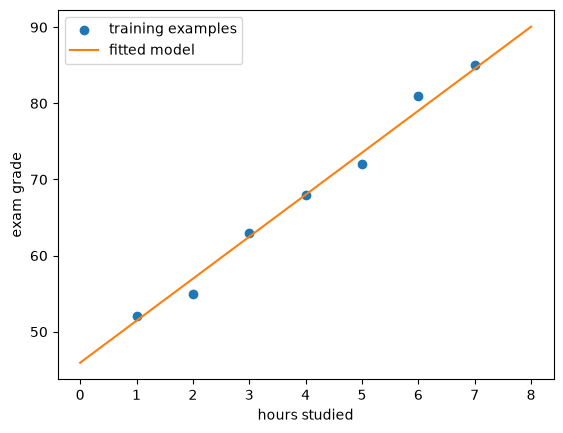

In [3]:
#| code-fold: true
#| code-summary: "Show plotting code"

hours_grid = pd.DataFrame({"hours": np.linspace(0, 8, 100)})
plt.scatter(study_data["hours"], study_data["grade"], label="training examples")
plt.plot(
    hours_grid["hours"],
    study_model.predict(hours_grid),
    color="tab:orange",
    label="fitted model",
)
plt.xlabel("hours studied")
plt.ylabel("exam grade")
plt.legend();

According to the fitted line, the predicted grade for a student who studies for about 5.5 hours is approximately 76%. This is a prediction from the model, not a guarantee about what the student will receive.

In [4]:
pd.Series(
    {
        "coefficient": study_model.coef_[0],
        "intercept": study_model.intercept_,
        "prediction_for_5.5_hours": study_model.predict(
            pd.DataFrame({"hours": [5.5]})
        )[0],
    }
)

coefficient                  5.517241
intercept                   45.931034
prediction_for_5.5_hours    76.275862
dtype: float64

The model makes a strong simplifying assumption: the predicted grade changes at a constant rate as study time increases. Because the learned coefficient is positive, it predicts that more study time always produces a higher grade. Is that plausible for every student and any number of hours?

In reality, additional study may have diminishing benefits, excessive studying may cause fatigue, and grades depend on many factors absent from this one-feature model. The fitted line would eventually predict grades above 100% if we extrapolated far enough. Moreover, an association between study time and grades does not by itself show that additional studying causes the predicted increase.

A linear model can still be useful when a straight line is a reasonable approximation over the range where predictions will be made. The line does not need to pass through every training example. Fitting must choose a coefficient and intercept from many possible values; shortly, we will look under the hood of `fit` and introduce the criterion used to make that choice.

With more features, each feature makes its own contribution. Suppose a model uses hours studied and practice sets completed. For one student,

| Feature | Value | Coefficient | Contribution |
|---|---:|---:|---:|
| Hours studied ($x_1$) | 5 | 4 | 20 |
| Practice sets ($x_2$) | 6 | 2 | 12 |
| Intercept ($b$) | | | 45 |

so the predicted grade is $20+12+45=77$. We can collect the feature values and coefficients into vectors:

$$
\mathbf{x}=
\begin{bmatrix}5\\6\end{bmatrix},
\qquad
\mathbf{w}=
\begin{bmatrix}4\\2\end{bmatrix}.
$$

The **dot product** $\mathbf{w}^{\mathsf T}\mathbf{x}$ multiplies corresponding entries and adds them. Therefore,

$$
\hat{y}
=\mathbf{w}^{\mathsf T}\mathbf{x}+b
=
\begin{bmatrix}4&2\end{bmatrix}
\begin{bmatrix}5\\6\end{bmatrix}
+45
=77.
$$

In general, this is shorthand for

$$
\hat{y}=w_1x_1+w_2x_2+\cdots+w_dx_d+b.
$$

For a complete dataset, we stack the examples as rows of a feature matrix $X$:

$$
X=
\begin{bmatrix}
5&6\\
2&3\\
7&5
\end{bmatrix},
\qquad
\mathbf{y}=
\begin{bmatrix}75\\62\\86\end{bmatrix}.
$$

Each column of $X$ is a feature, while $\mathbf{y}$ contains the observed targets. The model applies the same coefficient vector to every row:

$$
\hat{\mathbf{y}}=X\mathbf{w}+b,
$$

where $+b$ means adding the intercept to every prediction. With one feature, the prediction rule describes a line; with two features, a plane; and with more features, a **hyperplane**. The number of features changes, but the calculation remains a weighted sum plus an intercept.


### What happens during `fit`?

We have used `fit` to obtain a line, but how does it choose the coefficients and intercept? Many lines are possible. We need a criterion for comparing their predictions with the observed targets.

A **loss function** assigns a numerical penalty to a prediction based on its disagreement with the target. Combining these penalties across the training examples gives a criterion for comparing parameter choices. **Optimization** is the process of finding parameter values that reduce the fitting objective. Scikit-learn handles that computation when we call `fit`.

![The supervised-learning training loop: predictions are compared with targets and the resulting loss guides parameter updates.](img/supervised-learning-training.png){fig-alt="Features X enter a model, which produces predictions y hat. A loss compares predictions with targets y, and optimization updates the model parameters." fig-cap="An iterative view of fitting: predict, measure loss, and update parameters. Some fitting methods solve for parameters directly rather than using this loop." width="95%"}

The picture shows an iterative approach to optimization. The computational method depends on the estimator and solver; not every call to `fit` follows this loop. For now, the important distinction is between the prediction rule, the objective used to choose its parameters, and the algorithm used to carry out that choice.

### Measuring errors with mean squared error

Before comparing candidate lines, we need a way to describe how far a prediction is from the observed value. A **residual** is the observed target minus the predicted target:

$$
r_i=y_i-\hat y_i.
$$

For example, if a student's observed grade is 18 and the model predicts 16, the residual is $18-16=2$: the model underpredicts by two points. A negative residual means the model overpredicts. If we plot grades against study hours, the residual is the signed vertical gap from the fitted line to an observed point.

Suppose two candidate lines predict grades for two students whose observed grades are 18 and 20:

| Candidate | Predictions | Residuals ($y_i-\hat y_i$) | Squared errors | Mean squared error |
|---|---|---|---|---:|
| A | 16, 25 | $2$, $-5$ | 4, 25 | 14.5 |
| B | 21, 23 | $-3$, $-3$ | 9, 9 | 9 |

Candidate A is closer for the first student, but candidate B has the smaller average squared error. Squaring prevents positive and negative residuals from cancelling and gives large residuals relatively more weight. Doubling a residual's magnitude quadruples its squared contribution to the loss.

For $n$ examples, **mean squared error (MSE)** is

$$
\operatorname{MSE}=\frac{1}{n}\sum_{i=1}^{n}r_i^2
=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
=\frac{1}{n}\sum_{i=1}^{n}(y_i-\mathbf{x}_i^\mathsf{T}\mathbf{w}-b)^2.
$$

The symbol $\sum$ means add the terms for all examples; dividing by $n$ takes their mean. MSE is therefore the mean of the squared residuals.

::: {.callout-note collapse="true" title="Optional reference: MSE in vector and matrix notation"}

The following notation expresses the same squared-error calculation more compactly. You do not need to manipulate these expressions yet; they will be useful when studying how optimization algorithms learn coefficients.

For $n$ examples and $d$ features, we arrange the data and coefficients as

$$
X=\begin{bmatrix}
\mathbf{x}_1^\mathsf{T}\\
\vdots\\
\mathbf{x}_n^\mathsf{T}
\end{bmatrix}
=\begin{bmatrix}
x_{11}&\cdots&x_{1d}\\
\vdots&\ddots&\vdots\\
x_{n1}&\cdots&x_{nd}
\end{bmatrix},
\qquad
\mathbf{y}=\begin{bmatrix}y_1\\\vdots\\y_n\end{bmatrix},
\qquad
\mathbf{w}=\begin{bmatrix}w_1\\\vdots\\w_d\end{bmatrix}.
$$

Here $X$ has shape $n\times d$, $\mathbf{y}$ has shape $n\times1$, and $\mathbf{w}$ has shape $d\times1$. Each $\mathbf{x}_i$ is a $d\times1$ column vector; its transpose is row $i$ of $X$. Thus $\mathbf{x}_i^\mathsf{T}\mathbf{w}$ is a single weighted sum.

Writing each prediction using this dot product gives

$$
\operatorname{MSE}=\mathcal{L}(\mathbf{w},b)
=\frac{1}{n}\sum_{i=1}^{n}
\left(y_i-\mathbf{x}_i^\mathsf{T}\mathbf{w}-b\right)^2.
$$

To collect all residuals into one vector, let $\mathbf{1}_n$ be a column of $n$ ones:

$$
\hat{\mathbf{y}}=X\mathbf{w}+b\mathbf{1}_n,
\qquad
\mathbf{r}=\mathbf{y}-\hat{\mathbf{y}}.
$$

The term $b\mathbf{1}_n$ adds the intercept to every prediction; it is the explicit version of the shorthand $X\mathbf{w}+b$ used earlier. Both $\hat{\mathbf{y}}$ and $\mathbf{r}$ have shape $n\times1$.

The dot product $\mathbf{r}^\mathsf{T}\mathbf{r}$ multiplies each residual by itself and adds the results. For candidate A above,

$$
\mathbf{r}=\begin{bmatrix}2\\-5\end{bmatrix},
\qquad
\mathbf{r}^\mathsf{T}\mathbf{r}
=\begin{bmatrix}2&-5\end{bmatrix}\begin{bmatrix}2\\-5\end{bmatrix}
=4+25=29.
$$

Dividing by $n=2$ gives MSE $14.5$, just as in the table. In full matrix notation,

$$
\operatorname{MSE}
=\frac{1}{n}\mathbf{r}^\mathsf{T}\mathbf{r}
=\frac{1}{n}
\left(\mathbf{y}-X\mathbf{w}-b\mathbf{1}_n\right)^\mathsf{T}
\left(\mathbf{y}-X\mathbf{w}-b\mathbf{1}_n\right).
$$

A $1\times n$ row multiplied by an $n\times1$ column produces a single number. This is the same mean squared error as before, with the summation carried out by a dot product.

:::

**Ordinary least squares** chooses coefficients and an intercept that minimize squared-error loss. A low training loss means a good fit according to this criterion, not necessarily good predictions on unseen examples. We still need cross-validation to assess generalization. Also, the fitting loss need not be what an estimator's `score` method reports.

::: {.callout-reflection title="Why not just average the residuals?"}
A colleague proposes measuring prediction quality by averaging residuals without squaring them. A model has residuals of $+10$ and $-10$ on two examples. What does their measure report? Would that result tell us whether the predictions are accurate? Explain how MSE addresses the problem.
:::

::: {.callout-tip collapse="true" title="Solution"}
The average residual is zero because the two residuals cancel, even though both predictions are off by 10 units. MSE squares each residual before averaging, giving $(100+100)/2=100$. Opposite signs cannot cancel, so a model cannot achieve zero MSE unless every prediction equals its target.
:::


### Ridge regularization

Minimizing training MSE gives us a way to choose coefficients, but what if several choices fit almost equally well? Imagine two housing models with similar training predictions. One relies on large positive and negative feature contributions that almost cancel; the other uses smaller coefficients. When features contain overlapping information, small changes in the training sample can lead to large changes in the first model's coefficients.

We would like to fit the targets well without relying on unnecessarily large coefficients. **Regularization** introduces that preference into fitting. **Ridge regression** balances squared-error loss with a penalty on large coefficients, which can make the fitted model more stable and reduce overfitting. The prediction rule is still a weighted sum plus an intercept.

We will use scikit-learn's `Ridge` rather than `LinearRegression`: both make linear predictions, but `Ridge` includes this regularization penalty.

We introduce regularization at a high level here so that you can use these models and understand their main controls. In DSCI 573, you will explore regularization and its effects on model fitting and generalization in more depth.

Let's try `Ridge` on the King County housing dataset. Each row records an individual house sale, and the target, `price`, is the sale price in dollars. We will predict it using living area, bedroom and bathroom counts, number of floors, year built, and location.

We deliberately use a small set of numerical features to focus on the linear model. We omit the property identifier and sale date, and leave out ZIP code rather than treating its numeric labels as measurements. This is a simplified example, not a complete property-valuation system. The pipeline will standardize the selected features because they have very different units and ranges.


In [5]:
housing = pd.read_csv(DATA_DIR / "kc_house_data.csv")
housing_features = [
    "sqft_living", "bedrooms", "bathrooms", "floors", "yr_built", "lat", "long"
]
X_housing = housing[housing_features]
y_housing = housing["price"]
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=123
)

X_train_h.head()

,sqft_living,bedrooms,bathrooms,floors,yr_built,lat,long
14305,2170,3,2.75,1.5,1930,47.6389,-122.349
19844,3550,4,2.75,2.0,2014,47.4827,-122.131
2686,1210,3,3.25,2.0,2002,47.7114,-122.356
11926,2370,3,2.50,2.0,2003,47.5427,-121.863
13873,2250,5,1.75,1.0,1966,47.7217,-122.188


We begin with a mean-prediction baseline. We then place `StandardScaler` and `Ridge` in a pipeline so that the scaler is fit separately within each cross-validation fold.

Ridge uses squared errors and regularization to learn its coefficients. To compare the resulting predictions, the code below uses the estimators' default evaluation score, $R^2$. Fitting and evaluation have different jobs: the fitting objective chooses parameters; the evaluation score helps us assess predictions on held-out folds.


In [6]:
regression_models = {
    "mean baseline": DummyRegressor(),
    "scaled Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
}

regression_results = {}
for name, model in regression_models.items():
    scores = cross_validate(model, X_train_h, y_train_h, return_train_score=True)
    regression_results[name] = {
        "mean_train_score": scores["train_score"].mean(),
        "mean_cv_score": scores["test_score"].mean(),
    }

pd.DataFrame(regression_results).T

,mean_train_score,mean_cv_score
mean baseline,0.000000,-0.000077
scaled Ridge,0.601632,0.600872


An $R^2$ score of 1 means perfect predictions. A score of 0 means the squared errors equal those from always predicting the mean target of the data being evaluated; negative scores are possible when predictions are worse than that reference. Larger is better. The `DummyRegressor` learns a mean from its training portion, so its validation $R^2$ need not be exactly zero.

The Ridge model improves substantially over the mean-prediction baseline here. These $R^2$ values are evaluation scores, not the loss minimized during fitting. Chapter 8 compares squared and absolute errors and develops the distinction between fitting loss and evaluation score.

#### Controlling model complexity

The penalty gives Ridge a reason to prefer one coefficient combination over another even when their training errors are similar. It does not force all coefficients to be tiny: a larger coefficient can still be worthwhile if it improves the fit enough to offset its penalty. The hyperparameter `alpha` controls this trade-off.

::: {.callout-note collapse="true" title="Optional: What `Ridge` minimizes"}
Ordinary least squares chooses coefficients by minimizing squared-error loss. `Ridge` adds a penalty based on the squared coefficients:

$$
\text{quantity minimized by Ridge}
=
\sum_{i=1}^{n}(y_i-\hat y_i)^2
+
\alpha\sum_{j=1}^{d}w_j^2.
$$

The first term is the **sum** of squared residuals, matching scikit-learn's Ridge objective. Earlier we used their **mean**, MSE. Without a penalty, minimizing the sum or the mean selects the same coefficients because $n$ is fixed. With a penalty, their relative scaling matters: dividing the entire expression by $n$ gives MSE plus $(\alpha/n)\sum_j w_j^2$. Using MSE plus $\alpha\sum_j w_j^2$ would require a different numerical value of `alpha` to produce the same balance.

The first term rewards predictions close to the training targets. The second discourages large coefficients. The optimization procedure searches for coefficients that balance these two goals. The details of that optimization are beyond the scope of this book.
:::


The hyperparameter `alpha` controls the strength of regularization:

- A larger `alpha` discourages large coefficients more strongly, usually producing a less flexible model with a greater risk of underfitting.
- A smaller `alpha` allows the model to follow the training data more closely, usually producing a more flexible model with a greater risk of overfitting.

Changing `alpha` changes the preference for coefficients; the prediction rule remains linear. We use `Ridge` here so that we can control this preference. The appropriate positive value of `alpha` is data-dependent and can be selected using cross-validation.

Scaling matters because regularization acts on coefficient magnitudes. Without scaling, changing a feature from dollars to thousands of dollars changes the size of its coefficient and therefore how strongly that feature is affected by the penalty. This is why our `Ridge` pipeline includes `StandardScaler`.


In [7]:
alpha_results = []
for alpha in 10.0 ** np.arange(-3, 7):
    ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    scores = cross_validate(
        ridge_pipe, X_train_h, y_train_h, return_train_score=True
    )
    alpha_results.append(
        {
            "alpha": alpha,
            "mean_train_score": scores["train_score"].mean(),
            "mean_cv_score": scores["test_score"].mean(),
        }
    )

alpha_results_df = pd.DataFrame(alpha_results)
alpha_results_df

,alpha,mean_train_score,mean_cv_score
0,0.001,0.601632,0.600872
1,0.010,0.601632,0.600872
2,0.100,0.601632,0.600872
3,1.000,0.601632,0.600872
4,10.000,0.601631,0.600875
5,100.000,0.601560,0.600835
6,1000.000,0.596508,0.596023
7,10000.000,0.497925,0.498122
8,100000.000,0.189492,0.189751
9,1000000.000,0.026772,0.026749


The training and cross-validation scores are very similar across these values of `alpha`. Increasing regularization provides little improvement in cross-validation performance here. At very large `alpha`, both scores fall, indicating underfitting.

The best value is data-dependent. Small differences in cross-validation scores should not automatically be treated as meaningful improvements. We should select `alpha` using training-data cross-validation, rather than repeatedly checking the test set, as discussed in Chapter 6.

### Interpreting coefficients

After fitting the pipeline, we can inspect the coefficients learned by `Ridge`. Each coefficient describes how the model's prediction changes as its corresponding feature changes, **holding the other represented features fixed**. Because the pipeline scales the features before fitting, their numerical scales are comparable, making their coefficient magnitudes easier to compare.

A one-unit increase in a standardized feature corresponds to one training-set standard deviation in its original units. Its coefficient therefore describes a change in predicted house value in dollars for that increase, holding the other represented features fixed.


In [8]:
ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_pipe.fit(X_train_h, y_train_h)

ridge_coefficients = pd.Series(
    ridge_pipe.named_steps["ridge"].coef_,
    index=X_train_h.columns,
    name="coefficient",
).sort_values()
ridge_coefficients.to_frame()

,coefficient
yr_built,-66278.023300
bedrooms,-53967.179268
long,-22921.711895
floors,16743.938736
bathrooms,42383.802360
lat,82592.068682
sqft_living,269571.929217


For a concrete example, the training-set standard deviation of `sqft_living`, as computed by the fitted scaler, is about 915 square feet. Its Ridge coefficient is about \$269,572. Thus, increasing living area by about 915 square feet increases this model's predicted sale price by about \$269,572, holding the other represented features fixed. It does **not** mean a one-square-foot increase adds that amount.

A positive coefficient means that increasing the feature, while keeping the other represented features fixed, increases the model's prediction. A negative coefficient decreases the prediction. After scaling, a larger absolute coefficient generally means that the model's prediction changes more in response to a comparable change in that feature.

That interpretation needs several qualifications:

- The coefficient describes the fitted model, not necessarily how the world works. It is not a causal effect.
- Correlated features can share or exchange predictive information, making individual coefficients unstable or surprising.
- Without comparable scaling, coefficient magnitudes cannot be compared directly because a one-unit change means something different for each feature.
- A coefficient gives a constant change per unit. If the real relationship curves or depends on another feature, that summary may be inadequate.
- The intercept may not have a useful real-world interpretation if an all-zero feature vector is impossible or far outside the observed data.

Coefficients can help us understand how a model computes predictions, but they should be treated as evidence about the model rather than automatic feature importance or causal evidence.

::: {.callout-reflection title="Does a coefficient describe the effect of changing a house?"}
Inspect the coefficients for `sqft_living` and `bedrooms`. Why might a model assign a positive coefficient to living area but a negative coefficient to bedroom count? Does a negative bedroom coefficient establish that adding a bedroom will lower a house's sale price? Consider what it means to change bedroom count while holding living area and the other represented features fixed.
:::

::: {.callout-tip collapse="true" title="Explanation"}
The bedroom coefficient describes the model's prediction for a change in bedroom count while holding the other features, including total living area, fixed. This differs from adding a bedroom by extending a house and increasing its area. Related features can share predictive information, and omitted features may affect the fitted relationship. The coefficient does not establish a causal effect of renovation on sale price.
:::


#### Check your understanding: Interpret a standardized coefficient

Suppose a fitted housing pipeline standardizes living area using a training-set standard deviation of 800 square feet. The Ridge coefficient for standardized living area is \$160,000. Holding the other represented features fixed, how much does the model's prediction change for an increase of 400 square feet? Does this tell us what a homeowner would earn by building an extension?

::: {.callout-tip collapse="true" title="Solution"}
An increase of 400 square feet is $400/800=0.5$ standardized units, so the prediction increases by $0.5\times160{,}000=80{,}000$ dollars. This describes the fitted model's calculation, not the causal effect or financial return of an extension. An extension may also change other features, and the data do not establish what would happen after a renovation.
:::


## Logistic regression

### Making predictions with a linear score

Linear regression produces a numeric prediction directly. For classification, we instead need to choose among classes. Despite its name, **logistic regression** is a classifier. Like linear regression, it first computes a weighted sum:

$$
z = \mathbf{w}^{\mathsf T}\mathbf{x}+b.
$$

This value is often called the **decision score** or raw score. In binary classification, its sign determines which side of the decision boundary an example lies on.


Let's return to the Canada-USA cities classification problem from Chapter 1. The features are a city's longitude and latitude, and the target indicates whether it is in Canada or the United States.

![An aerial view of the Canada-USA border highlighted between forested areas.](img/canada-us-border.jpg){fig-alt="An aerial view of a section of the Canada-USA border, visible as a cleared line through a forest." fig-cap="The real Canada-USA border has geographic complications that cannot be captured by one straight line." width="75%"}

[Image source](https://sovereignlimits.com/blog/u-s-canada-border-history-disputes)

Alaska is an obvious complication: geography is not truly separated by one straight line. This makes the dataset useful for studying both a linear classifier and its limitations.

In [9]:
cities = pd.read_csv(DATA_DIR / "canada_usa_cities.csv")
X_cities = cities[["longitude", "latitude"]]
y_cities = cities["country"]
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cities, y_cities, test_size=0.2, random_state=123, stratify=y_cities
)

classification_models = {
    "most-frequent baseline": DummyClassifier(strategy="most_frequent"),
    "scaled logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(random_state=123)
    ),
}

classification_results = {}
for name, model in classification_models.items():
    scores = cross_validate(model, X_train_c, y_train_c, return_train_score=True)
    classification_results[name] = {
        "mean_train_accuracy": scores["train_score"].mean(),
        "mean_cv_accuracy": scores["test_score"].mean(),
    }

pd.DataFrame(classification_results).T

,mean_train_accuracy,mean_cv_accuracy
most-frequent baseline,0.610773,0.610695
scaled logistic regression,0.808394,0.808556


### Scores and the decision boundary

We fit the pipeline to examine a prediction. The model's `classes_` attribute records the class order. In binary logistic regression, a negative decision score selects `classes_[0]`, while a positive score selects `classes_[1]`. This ordering is deterministic; the model does not randomly designate the positive class.

In [10]:
logistic_pipe = make_pipeline(
    StandardScaler(), LogisticRegression(random_state=123)
)
logistic_pipe.fit(X_train_c, y_train_c)

example = X_train_c.iloc[[0]]
pd.DataFrame(
    {
        "decision_score": logistic_pipe.decision_function(example),
        "prediction": logistic_pipe.predict(example),
    }
)

,decision_score,prediction
0,-1.189584,Canada


In [11]:
logistic_pipe.named_steps["logisticregression"].classes_

array(['Canada', 'USA'], dtype=object)

The **decision boundary** contains feature values whose score is zero:

$$
\mathbf{w}^{\mathsf T}\mathbf{x}+b=0.
$$

With two features, this boundary is a line. With three, it is a plane; with $d$ features, it is a $(d-1)$-dimensional hyperplane. A linear classifier can still make mistakes on its training data: a linear boundary is the form of the rule, not a requirement that the classes be perfectly separable.

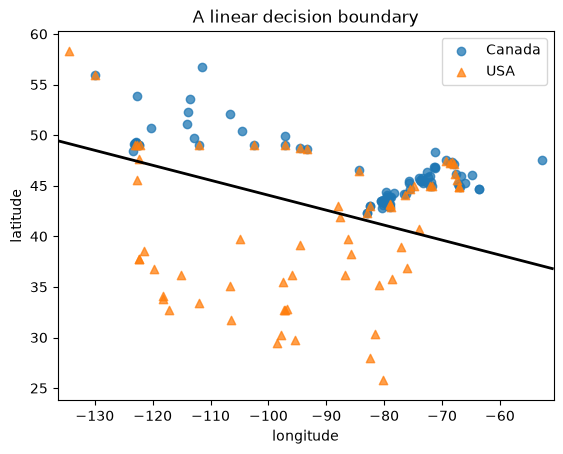

In [12]:
#| code-fold: true
#| code-summary: "Show plotting code"

x_min, x_max = X_train_c["longitude"].min() - 2, X_train_c["longitude"].max() + 2
y_min, y_max = X_train_c["latitude"].min() - 2, X_train_c["latitude"].max() + 2
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300),
)
grid = pd.DataFrame({"longitude": xx.ravel(), "latitude": yy.ravel()})
grid_scores = logistic_pipe.decision_function(grid).reshape(xx.shape)

for country, marker in zip(logistic_pipe.classes_, ["o", "^"]):
    mask = y_train_c == country
    plt.scatter(
        X_train_c.loc[mask, "longitude"],
        X_train_c.loc[mask, "latitude"],
        label=country,
        marker=marker,
        alpha=0.75,
    )
plt.contour(xx, yy, grid_scores, levels=[0], colors="black", linewidths=2)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.legend()
plt.title("A linear decision boundary");

### From scores to probabilities

The sign of the linear score lets us choose a country, but what if we want an estimated probability as well? The score itself cannot serve as a probability: a weighted sum can be negative or greater than 1.

We need a way to map scores to numbers between 0 and 1. Larger scores should give a larger probability of `classes_[1]`, and a score of zero, the decision boundary, should give equal probabilities to both classes. Logistic regression uses the **sigmoid function** to provide this mapping:

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

For a very negative score, the result is close to 0; at zero it is 0.5; for a very positive score, it is close to 1. This result is the model's estimated probability of `classes_[1]`. Choosing the more probable class therefore gives the same decision as using the sign of the score.

The sigmoid defines the probability model used by logistic regression. Applying it to an arbitrary score does not by itself guarantee useful probability estimates; fitting and evaluating the model still matter.


In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

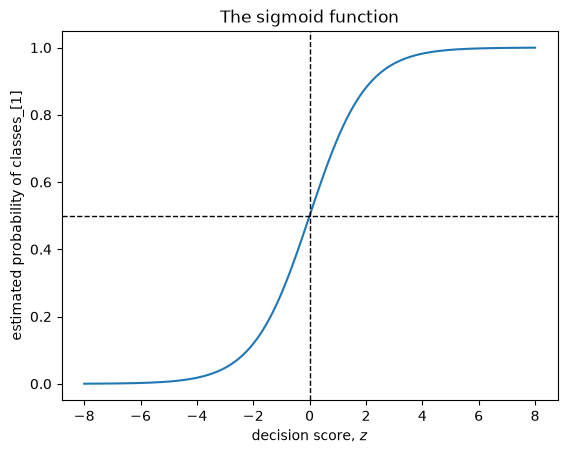

In [14]:
#| code-fold: true
#| code-summary: "Show plotting code"

scores = np.linspace(-8, 8, 400)
plt.plot(scores, sigmoid(scores))
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)
plt.xlabel("decision score, $z$")
plt.ylabel("estimated probability of classes_[1]")
plt.title("The sigmoid function");

In [15]:
decision_score = logistic_pipe.decision_function(example)[0]
pd.Series(
    {
        "sigmoid(decision_score)": sigmoid(decision_score),
        "predict_proba for classes_[1]": logistic_pipe.predict_proba(example)[0, 1],
    }
)

sigmoid(decision_score)          0.233333
predict_proba for classes_[1]    0.233333
dtype: float64

`predict_proba` returns one column per class in the order given by `classes_`. For binary classification the two probabilities sum to one. The larger probability determines the default hard prediction.

An estimated probability is useful, but it should not automatically be treated as trustworthy confidence. A model can assign a high probability to an incorrect prediction, particularly when its assumptions are inadequate or deployment examples differ from its training data. Chapter 8 uses log loss to evaluate probability predictions, while a detailed treatment of probability calibration is beyond this book.

#### Probabilities near and far from the fitted boundary

For this fitted binary model, points close to its straight decision boundary have scores near zero and probabilities near 0.5 for both countries. Farther away, the probability of the **predicted class** becomes larger. The probability of one particular country rises on one side of the boundary and falls on the other.

This refers to perpendicular distance in the standardized feature space used by the model, not distance in kilometres to the actual national border. The fitted line is an approximation to the geographic separation. A city can be close to the real border while being far from the model's line.

Let's inspect training cities near the fitted boundary and farther away on either side. These examples explain the fitted rule; they are not an independent evaluation of its predictive performance.

The dataset provides coordinates and country labels, but no city names. We label three concrete examples A, B, and C so that you can match their locations, probabilities, and table rows.


In [16]:
train_predictions = X_train_c.copy()
train_predictions["True class"] = y_train_c
train_predictions["predicted"] = logistic_pipe.predict(X_train_c)
train_predictions["decision_score"] = logistic_pipe.decision_function(X_train_c)
city_probabilities = logistic_pipe.predict_proba(X_train_c)
for j, country in enumerate(logistic_pipe.classes_):
    train_predictions[f"P({country})"] = city_probabilities[:, j]
train_predictions["predicted_probability"] = city_probabilities.max(axis=1)

example_indices = [
    train_predictions["decision_score"].abs().idxmin(),
    train_predictions["decision_score"].idxmin(),
    train_predictions["decision_score"].idxmax(),
]
selected_cities = train_predictions.loc[example_indices].copy()
selected_cities.index = pd.Index(["A", "B", "C"], name="city example")
selected_cities["position"] = [
    "near fitted boundary", "far on class 0 side", "far on class 1 side"
]
selected_cities.round(3)

,longitude,latitude,True class,predicted,decision_score,P(Canada),P(USA),predicted_probability,position
city example,,,,,,,,,
A,-122.330,47.604,USA,Canada,-0.059,0.515,0.485,0.515,near fitted boundary
B,-111.388,56.729,Canada,Canada,-2.706,0.937,0.063,0.937,far on class 0 side
C,-80.194,25.774,USA,USA,3.786,0.022,0.978,0.978,far on class 1 side


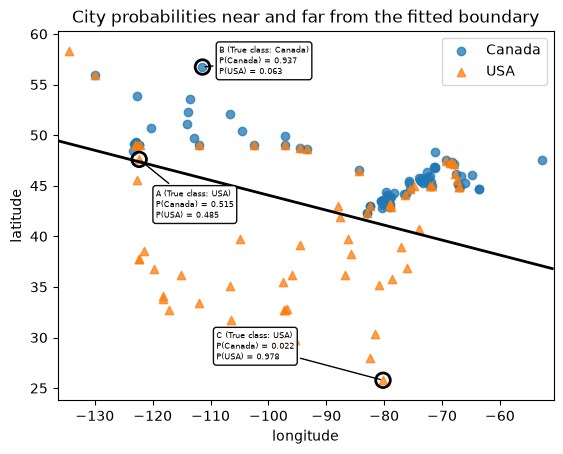

In [17]:
#| code-fold: true
#| code-summary: "Show plotting code"

fig, map_ax = plt.subplots()
colors = ["tab:blue", "tab:orange"]
for country, marker, color in zip(logistic_pipe.classes_, ["o", "^"], colors):
    mask = y_train_c == country
    map_ax.scatter(
        X_train_c.loc[mask, "longitude"], X_train_c.loc[mask, "latitude"],
        alpha=0.75, marker=marker, color=color, label=country,
    )
map_ax.contour(xx, yy, grid_scores, levels=[0], colors="black", linewidths=2)
offsets = {"A": (12, -42), "B": (12, -5), "C": (-120, 15)}
for label, row in selected_cities.iterrows():
    map_ax.scatter(row["longitude"], row["latitude"], s=110,
                   facecolors="none", edgecolors="black", linewidths=2)
    probability_text = "\n".join(
        f"P({country}) = {row[f'P({country})']:.3f}"
        for country in logistic_pipe.classes_
    )
    map_ax.annotate(
        f"{label} (True class: {row['True class']})\n{probability_text}",
        (row["longitude"], row["latitude"]), xytext=offsets[label],
        textcoords="offset points", fontsize=6,
        bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "alpha": 0.95},
        arrowprops={"arrowstyle": "-", "color": "black"},
    )
map_ax.set(xlabel="longitude", ylabel="latitude", title="City probabilities near and far from the fitted boundary")
map_ax.legend();

City A is the training example closest to the fitted boundary in standardized feature space. Its two probabilities are close to 0.5. Cities B and C lie far from the line on opposite sides: the model assigns a high probability to one country for B and to the other for C. Compare their true and predicted classes in the table; a large probability does not establish that a prediction is correct.

The line is the model's decision boundary, not a map of the actual national border.

In [18]:
train_predictions.loc[
    train_predictions["True class"] != train_predictions["predicted"]
].sort_values("predicted_probability", ascending=False).head(5)

,longitude,latitude,True class,predicted,decision_score,P(Canada),P(USA),predicted_probability
1,-134.4197,58.3019,USA,Canada,-2.254809,0.905065,0.094935,0.905065
24,-68.3219,47.3556,USA,Canada,-1.965534,0.877131,0.122869,0.877131
22,-69.2275,47.4562,USA,Canada,-1.957328,0.876243,0.123757,0.876243
23,-68.5897,47.2587,USA,Canada,-1.931892,0.873459,0.126541,0.873459
25,-67.9353,47.1575,USA,Canada,-1.930796,0.873338,0.126662,0.873338


The table of incorrect predictions above deliberately searches for confident mistakes rather than relying on hard-coded row numbers. Some cities in Alaska can be geographically far from the model's straight boundary even though they belong to the United States. The model can therefore be confidently wrong because its linear representation cannot express the actual geography.

This is a general lesson: probability estimates are conditional on the model, its features, and the data used to fit it. A high value from `predict_proba` is not a guarantee.

::: {.callout-reflection title="Does a high probability guarantee a correct prediction?"}
Explain why a city far from the fitted line can receive a high probability for the wrong country.
:::

::: {.callout-tip collapse="true" title="Explanation"}
The probability comes from the fitted linear score, so a large score magnitude produces an extreme probability even when the line misrepresents the geography. The straight boundary cannot reproduce the bends and disconnected regions of the actual border.
:::


#### Interpreting logistic-regression coefficients

A positive coefficient increases the decision score, and hence the probability of `classes_[1]`, when that represented feature increases and the others are held fixed. A negative coefficient moves the score in the other direction. Check `classes_` before attaching country names to those directions.

Unlike a linear-regression coefficient, a logistic-regression coefficient does not describe a fixed change in the predicted target or a fixed percentage-point change in probability. The sigmoid is steeper near zero and flatter at extreme scores, so the probability change depends on the starting score. With standardized features, the coefficient is the score change for a one-training-standard-deviation increase in the original feature. As before, these are properties of the model, not causal claims.


### What happens during `fit`? Log loss and binary cross-entropy

We now have a way to turn coefficients into probabilities. To fit those coefficients, we need to decide what makes one set of probability predictions better than another. Accuracy counts a prediction as correct whether the model assigns the true class probability 0.51 or 0.99. Should a fitting loss treat these predictions differently?

Suppose a city's true class is Canada. We would like to give a prediction of 0.99 for Canada less loss than a prediction of 0.51. Now suppose the city is actually in the United States: assigning Canada probability 0.99 should incur a much larger penalty than assigning it 0.51. The model has committed much more strongly to the wrong country.

Before looking at a formula, consider the behaviour we want from the loss:

- **Confident and correct** $\to$ very small loss.
- **Hesitant and correct** $\to$ somewhat larger loss.
- **Hesitant and incorrect** $\to$ larger loss.
- **Confident and incorrect** $\to$ very large loss.

Here, confident means assigning a high probability to the predicted class; hesitant means the two class probabilities are close to 0.5. A confident mistake therefore assigns a very low probability to the true class. These descriptions refer to the model's probability estimates, not a guarantee that they are reliable.

**Log loss** gives us this behaviour by looking at the probability assigned to the **true class**, meaning the example's observed label. Let $p_{\text{true class}}$ be the probability the model assigns to that label:

$$
\ell=-\log(p_{\text{true class}}).
$$

Here $\log$ is the natural logarithm. Assigning the true class probability near 1 gives loss near zero; assigning it probability near zero gives a large loss. For example, probabilities 0.9 and 0.1 for the true class give losses approximately 0.105 and 2.303, respectively.

The following plot connects this formula to the four cases above. Moving right means assigning more probability to the true class, so the loss decreases.


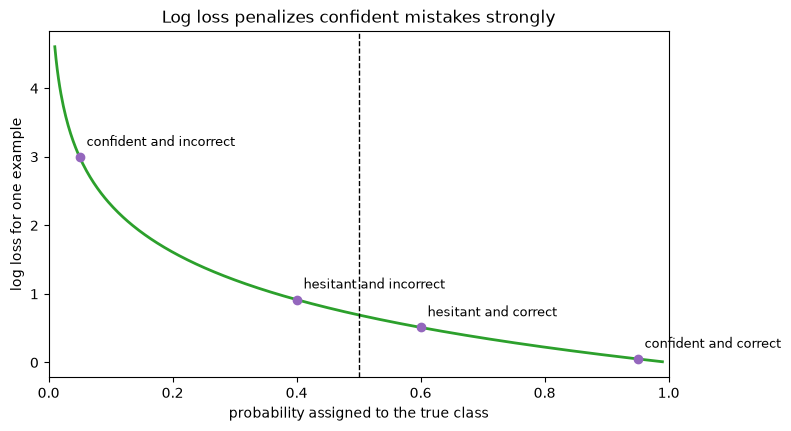

In [19]:
#| code-fold: true
#| code-summary: "Show plotting code"

probability_true_class = np.linspace(0.01, 0.99, 500)
example_loss = -np.log(probability_true_class)

case_probabilities = np.array([0.05, 0.40, 0.60, 0.95])
case_labels = [
    "confident and incorrect",
    "hesitant and incorrect",
    "hesitant and correct",
    "confident and correct",
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(probability_true_class, example_loss, color="tab:green", linewidth=2)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.scatter(
    case_probabilities,
    -np.log(case_probabilities),
    color="tab:purple",
    zorder=3,
)

for probability, label in zip(case_probabilities, case_labels):
    ax.annotate(
        label,
        (probability, -np.log(probability)),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_xlabel("probability assigned to the true class")
ax.set_ylabel("log loss for one example")
ax.set_title("Log loss penalizes confident mistakes strongly")
ax.set_xlim(0, 1);

For a binary target, encode `classes_[0]` as 0 and `classes_[1]` as 1, and let $p_i$ be the estimated probability of class 1. The same loss can be written as **binary cross-entropy**:

$$
\ell_i=-\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].
$$

If $y_i=1$, the second term disappears and the loss is $-\log(p_i)$. If $y_i=0$, the first term disappears and the loss is $-\log(1-p_i)$. In both cases, it is the negative log of the probability assigned to the true class. These are two expressions for the same loss, not two different fitting methods.

Fitting logistic regression combines the mean of these losses over training examples with a regularization penalty.

### Regularization and the role of `C`

As with `Ridge`, `LogisticRegression` minimizes its loss together with a regularization penalty. Its `C` hyperparameter controls regularization in the opposite direction from the `alpha` of `Ridge`:

- Smaller `C` means stronger regularization and usually a less flexible model.
- Larger `C` means weaker regularization and usually a more flexible model.

This reversal is easy to forget: `alpha` directly controls regularization strength, whereas `C` controls inverse regularization strength.


In [20]:
C_results = []
for C in 10.0 ** np.arange(-4, 5):
    model = make_pipeline(
        StandardScaler(), LogisticRegression(C=C, random_state=123)
    )
    scores = cross_validate(model, X_train_c, y_train_c, return_train_score=True)
    C_results.append(
        {
            "C": C,
            "mean_train_accuracy": scores["train_score"].mean(),
            "mean_cv_accuracy": scores["test_score"].mean(),
        }
    )

pd.DataFrame(C_results)

,C,mean_train_accuracy,mean_cv_accuracy
0,0.0001,0.610773,0.610695
1,0.0010,0.610773,0.610695
2,0.0100,0.714084,0.718895
3,0.1000,0.799405,0.802496
4,1.0000,0.808394,0.808556
5,10.0000,0.812872,0.808556
6,100.0000,0.814375,0.808556
7,1000.0000,0.814375,0.808556
8,10000.0000,0.814375,0.808556


#### Check your understanding: Regularization and model complexity (multiple select)

**Select all statements that are true.**

- (A) Increasing `alpha` usually makes a `Ridge` model less flexible.
- (B) Increasing `C` strengthens regularization in `LogisticRegression`.
- (C) Scaling helps ensure that the regularization penalty treats coefficient magnitudes comparably across features.
- (D) We should choose `alpha` by finding the value with the best test score.
- (E) Extremely strong regularization can cause underfitting.

::: {.callout-tip collapse="true" title="Solution"}
A, C, and E are true. Larger `alpha` means stronger regularization for `Ridge`, but larger `C` means weaker regularization for `LogisticRegression`. Hyperparameters should be selected using training data and validation or cross-validation, not the test set.
:::


#### Check your understanding: Scores, probabilities, and log loss (multiple select)

**Select all statements that are true for a fitted binary logistic-regression model.**

- (A) A negative decision score predicts `classes_[0]`.
- (B) A decision score of zero corresponds to a probability of 0.5 for `classes_[1]`.
- (C) A decision score of 2 gives `classes_[1]` a higher probability than a score of -3.
- (D) A decision score of -3 is closer to the decision boundary than a score of zero.
- (E) A confident incorrect prediction receives less log loss than a hesitant incorrect prediction.

::: {.callout-tip collapse="true" title="Solution"}
A, B, and C are true. The decision boundary is at a score of zero, and the sigmoid function increases as the score increases. A confident incorrect prediction assigns very little probability to the true class and therefore receives a large log loss.
:::


## Strengths and limitations of linear models

### What does a fitted model retain?

Suppose we double the number of training examples while keeping the same features. Does the fitted model need to store twice as much information to make predictions?

For a linear model, fitting learns coefficients and an intercept. With 100 represented features, a linear-regression or binary logistic-regression model has 100 coefficients and one intercept, whether it learns from 1,000 examples or one million. More training examples can change their fitted values, but not their number. We call this a **parametric model**: the number of parameters is fixed for a fixed feature representation and prediction task.

By contrast, $k$-NN retains the training examples and their targets to consult during prediction. Doubling the training set increases what it stores, and a straightforward neighbour search has more examples to examine. It is commonly called **non-parametric** because its fitted representation is not restricted to a fixed-size collection of parameters as training data grow.

| Question | Linear model | $k$-NN |
|---|---|---|
| What does fitting retain for prediction? | Coefficients and an intercept | Training examples and targets |
| What changes when training rows are added? | Parameter values can change; their number stays fixed for fixed features and task | Stored examples grow |
| How are predictions calculated? | A weighted sum, with a sigmoid for binary logistic regression | Targets of nearby training examples |

“Non-parametric” does not mean “no hyperparameters”: $k$-NN still has settings such as the number of neighbours. “Parametric” does not mean small or unable to overfit: 100,000 word features give a binary linear classifier 100,001 parameters.

The fixed-representation qualification matters. If fitting a vectorizer on more documents expands its vocabulary, the number of features changes and a linear model can gain coefficients. More rows alone do not increase its parameter count when the represented features and classes stay fixed.

::: {.callout-reflection title="What changed: examples or features?"}
A team doubles its text training data and finds that logistic regression now has more coefficients. Does this contradict its description as parametric? What would you check?
:::

::: {.callout-tip collapse="true" title="Solution"}
Check whether the learned vocabulary or the set of target classes changed. The fixed-parameter-count statement assumes both stay fixed. More training rows alone do not add coefficients when the representation and classes are unchanged.
:::

### When are linear models useful?

Linear models are often strong baselines. They are typically fast to predict with, scale to many examples and features, and work well with sparse representations such as bag-of-words. Their coefficients make the calculation behind a prediction relatively transparent. Regularization provides a direct way to control model complexity.

Their central restriction is also clear: the prediction is linear in the represented features. Logistic regression separates classes with a hyperplane, and linear regression assigns the same coefficient to a feature throughout the feature space. Curved relationships, local patterns, and interactions may therefore be missed unless useful transformed or interaction features are supplied.

This limitation does not mean the raw data must literally follow a straight line. A linear model is linear in its **features**. Later feature-engineering techniques can create features that let a linear model represent some nonlinear relationships, although every transformation introduces new assumptions and potential complexity.

For a practical starting point, try a regularized linear model when the representation has many sparse features, fast prediction matters, or an additive rule is plausible. Compare it with a more flexible model using training-data cross-validation when local patterns or curved relationships seem important. Inspect mistakes as well as aggregate scores.

The weighted sum we developed here also appears inside neural networks. Combining learned weighted sums with nonlinear transformations allows those models to represent more complex relationships. Simply stacking linear operations without nonlinear transformations would still produce a linear rule.


## Summary

- Linear models predict using a weighted sum of represented features and an intercept. Vector and matrix notation expresses the same calculation for one example or a complete dataset.
- Linear regression predicts numeric targets. Mean squared error (MSE) measures the average squared residual, where a residual is the observed target minus the prediction.
- Ridge balances squared-error loss with a penalty on large coefficients. Larger `alpha` means stronger regularization, which can reduce overfitting but can also cause underfitting.
- Logistic regression converts a linear score into a class probability using the sigmoid function. It fits using binary cross-entropy (log loss) together with regularization, penalizing confident mistakes particularly strongly.
- Larger `C` means weaker regularization in logistic regression, the opposite direction from Ridge's `alpha`. Select these hyperparameters using training-data cross-validation.
- Coefficients explain the fitted calculation, with care about scaling, correlated features, and the distinction between prediction and causation. Linear models may miss relationships their feature representation cannot express, and high predicted probabilities do not guarantee correct predictions.

- Linear models are parametric: their parameter count stays fixed for fixed features and classes. Non-parametric models such as $k$-NN retain a representation that grows with training data, and can still have hyperparameters.

In Chapter 8, we will extend classification to more than two classes, compare ways of measuring prediction errors, and bring these models into the complete supervised-learning workflow.
